# 13a. 실험 6 (판정) — 계절 사진을 넣으면 처음 보는 지역에서도 탄소가 더 맞는가

**한 줄 요약:** 지금 모델(v1, 피처 38개)에 계절 사진 5장 정보(v2, 25개)를 더한 **v1+계절(63개)**을 05와 똑같은 LORO(8곳 × 시드 5 = 40폴드)로 돌려, v1보다 지역별 탄소 오차가 줄어드는지 본다.

**쉬운 설명**
- 지금 모델은 숲을 여름 사진 한 장 + 겨울 사진 한 장으로 본다. 겨울에 잎이 지는 낙엽송은 활엽처럼 보일 수 있다
- 여기에 3–4·5–6·7–8·9–10·11–12월 사진 5장을 더한다. **바뀌는 건 "계절 정보 추가" 하나뿐**이라 결과가 나오면 원인이 분명하다
- v1 쪽은 **다시 학습하지 않는다.** 09번이 저장해 둔 v1 확률(`exp4c_folds`)을 그대로 쓴다 → 시간 절반
- 학습 표본은 05와 **같은 난수로 같은 픽셀**을 뽑는다. 계절 값이 없는 픽셀(봉화 0.8%)만 빼고, 평가도 두 모델 모두 같은 픽셀에서 한다

**끊겨도 이어서 돌릴 수 있다:** 폴드마다 파일로 저장한다. 끊기면 **런타임 → 모두 실행**만 다시 하면 끝난 폴드는 건너뛰고 남은 것만 돈다. (12번과 달리 이 노트북은 "모두 실행"이 안전하다)

**순서:** [1] 설정 → [2] 데이터 → [3] 검산 → [4] 학습 전 진단(기록) → [5] 사전 기록 → [6] LORO 40폴드 (약 1.5–2시간 [추정]) → [7] 모으기 → [8] 결과·판정 → [9] 낙엽송 확인 → [10] 피처 중요도 → [11] 그림

다음 파일 `13b`(v2 2클래스, 혼효 15:85 검증)는 이 결과를 본 뒤 만든다.

In [2]:
# [1] 설정 — 05와 같은 값
!pip install -q rasterio

import os, json, time, gc, warnings
import numpy as np
import pandas as pd
import rasterio
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
import matplotlib.pyplot as plt
from google.colab import drive
warnings.filterwarnings('ignore', category=RuntimeWarning)

drive.mount('/content/drive')
D        = '/content/drive/MyDrive/forest/data'
OUT      = '/content/drive/MyDrive/forest/outputs'
V1_DIR   = f'{OUT}/exp4c_folds'      # 09번 v1 확률 (재학습 안 함)
FOLD_DIR = f'{OUT}/exp6_folds'
os.makedirs(FOLD_DIR, exist_ok=True)

TRAIN_REGIONS = ['inje', 'hongcheon', 'gangneung', 'pyeongchang',
                 'bonghwa', 'geumsan', 'geochang', 'suncheon']
KR = {'inje': '인제', 'hongcheon': '홍천', 'gangneung': '강릉', 'pyeongchang': '평창',
      'bonghwa': '봉화', 'geumsan': '금산', 'geochang': '거창', 'suncheon': '순천'}
LAT   = {'inje': 38.04, 'hongcheon': 37.75, 'gangneung': 37.71, 'pyeongchang': 37.54,
         'bonghwa': 36.92, 'geumsan': 36.13, 'geochang': 35.71, 'suncheon': 35.01}
LARCH = {'inje': 19.0, 'hongcheon': 37.4, 'gangneung': 11.0, 'pyeongchang': 45.8,
         'bonghwa': 16.7, 'geumsan': 19.5, 'geochang': 11.7, 'suncheon': 0.0}   # 05와 같은 값 (참고)
LARCH_CODE = 13                     # KOFTR_GROU 낙엽송

C    = {1: 79.25, 2: 101.02, 3: 92.01}        # 확정계수. 구계수 사용 금지
CVEC = np.array([C[1], C[2], C[3]])

SEEDS              = [16, 17, 18, 19, 20]
N_TRAIN_PER_REGION = 30_000
RF_PARAMS = dict(n_estimators=80, min_samples_leaf=20, max_features='sqrt',
                 class_weight='balanced', n_jobs=-1)          # 05와 같음

SEASON_TAGS = ['s1', 's2', 's3', 's4', 's5']
SEASON_KR   = {'s1': '3–4월', 's2': '5–6월', 's3': '7–8월', 's4': '9–10월', 's5': '11–12월'}

B10 = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
NAMES1 = ([f's_{b}' for b in B10] + [f'w_{b}' for b in B10]
          + ['s_ndvi', 'w_ndvi', 's_ndmi', 'w_ndmi', 'd_ndvi', 'd_ndmi']
          + [f'{base}_{st}{w}' for base in ('s_ndvi', 'w_ndvi', 'd_ndvi') for w in (5, 15) for st in ('mu', 'sd')])
assert len(NAMES1) == 38

print('sklearn', sklearn.__version__, '/ CPU 코어', os.cpu_count())
print('탄소계수', C)

Mounted at /content/drive
sklearn 1.6.1 / CPU 코어 2
탄소계수 {1: 79.25, 2: 101.02, 3: 92.01}


In [3]:
# [2] 데이터 — v1 캐시(_s05) + v2 캐시(_v2) + 수종(낙엽송) 조회
X1, X2, Y, OK, NTOT, LX = {}, {}, {}, {}, {}, {}
NAMES2 = None
for r in TRAIN_REGIONS:
    z1 = np.load(f'{OUT}/{r}_s05.npz')
    z2 = np.load(f'{OUT}/{r}_v2.npz')
    assert len(z1['y']) == len(z2['y']) and (z1['y'] == z2['y']).all() and (z1['tile'] == z2['tile']).all(), \
        f'{r}: v1·v2 캐시 픽셀이 다름 — 멈추고 보고'
    X1[r], X2[r], Y[r], OK[r] = z1['X'], z2['X2'], z1['y'], z2['ok']
    NTOT[r] = int(z1['n_total'])
    if NAMES2 is None:
        NAMES2 = [str(s) for s in z2['names']]
    with rasterio.open(f'{D}/{r}_species.tif') as s:
        sp = s.read(1)
    LX[r] = (sp[z2['rows'], z2['cols']] == LARCH_CODE)       # 픽셀별 낙엽송 여부
    del sp, z1, z2; gc.collect()
NAMES = NAMES1 + NAMES2
assert len(NAMES) == 63

rows = []
for r in TRAIN_REGIONS:
    y, ok, lx = Y[r], OK[r], LX[r]
    rows.append(dict(지역=KR[r], 표본=len(y), 값있음=f'{ok.mean()*100:.1f}%',
                     침엽=f'{(y==1).mean()*100:.1f}', 활엽=f'{(y==2).mean()*100:.1f}', 혼효=f'{(y==3).mean()*100:.1f}',
                     침엽중_낙엽송=f'{lx[y==1].mean()*100:.1f}' if (y==1).any() else '-',
                     참고_05값=LARCH[r]))
print(pd.DataFrame(rows).to_string(index=False))
print('\n침엽중_낙엽송 = 수종 래스터 조회값(이번 표본). 참고_05값 = 05에 적어 둔 값(기준이 다를 수 있음, 크게 다르면 알려 주세요)')
print(f'RAM: v1 {sum(X1[r].nbytes for r in TRAIN_REGIONS)/1e9:.2f} GB + v2 {sum(X2[r].nbytes for r in TRAIN_REGIONS)/1e9:.2f} GB')

지역     표본    값있음   침엽   활엽   혼효 침엽중_낙엽송  참고_05값
인제 600263 100.0% 45.4 41.7 12.8    19.0    19.0
홍천 599525 100.0% 37.6 49.0 13.3    37.4    37.4
강릉 600079 100.0% 40.5 48.7 10.8    11.0    11.0
평창 600530 100.0% 44.2 46.2  9.7    45.9    45.8
봉화 599540  99.2% 60.3 32.8  6.9    16.8    16.7
금산 600247 100.0% 32.5 51.4 16.2    19.5    19.5
거창 601114 100.0% 50.3 29.6 20.1    11.7    11.7
순천 600845 100.0% 51.9 37.9 10.2     0.0     0.0

침엽중_낙엽송 = 수종 래스터 조회값(이번 표본). 참고_05값 = 05에 적어 둔 값(기준이 다를 수 있음, 크게 다르면 알려 주세요)
RAM: v1 0.73 GB + v2 0.48 GB


In [4]:
# [3] 검산 — v2 값 범위, v1 여름과 v2 여름이 같은 곳을 찍었는지, 09 폴드 파일 존재
for r in TRAIN_REGIONS:
    v = X2[r][OK[r]]
    assert np.isfinite(v).all(), f'{r}: 값 있음 픽셀에 NaN'
    p99 = np.percentile(v[:, :20], 99)
    assert p99 < 2.0, f'{r}: v2 밴드 스케일 이상 {p99:.2f}'

j_v1_sB8, j_v1_sB4 = NAMES1.index('s_B8'), NAMES1.index('s_B4')
j_v2_s3B8, j_v2_s3B4 = NAMES2.index('s3_B8'), NAMES2.index('s3_B4')
print(f'{"지역":6s} {"여름NDVI v1(6–9월)":>18s} {"v2 7–8월":>10s} {"B8 상관":>8s}   (같은 픽셀이면 상관이 높아야 함)')
for r in TRAIN_REGIONS:
    ok = OK[r]
    a, b = X1[r][ok, j_v1_sB8], X2[r][ok, j_v2_s3B8]
    rr = np.corrcoef(a, b)[0, 1]
    print(f'{KR[r]:6s} {np.median(X1[r][ok, 20]):18.3f} {np.median(X2[r][ok, NAMES2.index("s3_ndvi")]):10.3f} {rr:8.2f}')
    assert rr > 0.5, f'{r}: v1·v2 여름 B8 상관 {rr:.2f} — 픽셀이 어긋났을 수 있음, 멈추고 보고'

miss = [f's{s}_{r}' for s in SEEDS for r in TRAIN_REGIONS if not os.path.exists(f'{V1_DIR}/s{s}_{r}.npz')]
assert not miss, f'09 v1 폴드 파일 없음 {miss[:5]} … — 멈추고 보고'
print('\n검산 통과: v2 값 범위 정상, v1·v2 같은 픽셀, 09 폴드 40개 있음')

지역        여름NDVI v1(6–9월)    v2 7–8월    B8 상관   (같은 픽셀이면 상관이 높아야 함)
인제                  0.881      0.885     0.98
홍천                  0.878      0.885     0.97
강릉                  0.878      0.877     0.99
평창                  0.880      0.883     0.97
봉화                  0.874      0.873     0.99
금산                  0.886      0.890     0.99
거창                  0.871      0.875     0.99
순천                  0.868      0.874     0.99

검산 통과: v2 값 범위 정상, v1·v2 같은 픽셀, 09 폴드 40개 있음


In [5]:
# [4] 학습 전 진단 (기록만, 판정 아님) — 계절별로 침엽·활엽이 지역 간 얼마나 일관되게 갈리나
#   비율 지표는 쓰지 않는다(53-2 결함). 중앙값·뒤집힌 쌍 수만 본다.
def season_cols():
    out = [('v1 여름(6–9월)', X1, NAMES1.index('s_ndvi')), ('v1 겨울(11–2월)', X1, NAMES1.index('w_ndvi'))]
    out += [(f'v2 {SEASON_KR[t]}', X2, NAMES2.index(f'{t}_ndvi')) for t in SEASON_TAGS]
    return out

diag = []
for lab, XX, j in season_cols():
    cm = np.array([np.median(XX[r][OK[r] & (Y[r] == 1), j]) for r in TRAIN_REGIONS])
    bm = np.array([np.median(XX[r][OK[r] & (Y[r] == 2), j]) for r in TRAIN_REGIONS])
    sgn = np.sign(np.median(cm - bm))                           # 이 계절의 전체 방향 (침엽>활엽이면 +)
    flips = sum(sgn * (cm[i] - bm[k]) < 0 for i in range(8) for k in range(8) if i != k)
    lx_all = np.concatenate([XX[r][OK[r] & (Y[r] == 1) & LX[r], j] for r in TRAIN_REGIONS])
    nl_all = np.concatenate([XX[r][OK[r] & (Y[r] == 1) & ~LX[r], j] for r in TRAIN_REGIONS])
    br_all = np.concatenate([XX[r][OK[r] & (Y[r] == 2), j] for r in TRAIN_REGIONS])
    diag.append({'계절': lab,
                 '침엽 중앙값 범위(8곳)': f'{cm.min():.3f}–{cm.max():.3f}',
                 '활엽 중앙값 범위(8곳)': f'{bm.min():.3f}–{bm.max():.3f}',
                 '지역안 차이 평균': f'{np.mean(cm - bm):+.3f}',
                 '지역간 뒤집힘(/56)': int(flips),
                 '낙엽송': f'{np.median(lx_all):.3f}', '다른 침엽': f'{np.median(nl_all):.3f}', '활엽': f'{np.median(br_all):.3f}'})
DIAG = pd.DataFrame(diag)
DIAG.to_csv(f'{OUT}/exp6_diag_season.csv', index=False)
print(DIAG.to_string(index=False))
print('\n읽는 법: 뒤집힘 = A지역 침엽이 B지역 활엽보다 "반대쪽"인 쌍 수. 적을수록 그 계절 사진이 지역이 달라도 일관되게 가른다.')
print('        오른쪽 세 칸 = 8곳 합친 NDVI 중앙값. 낙엽송이 "다른 침엽"과 가깝고 활엽과 먼 계절이 있으면 그 사진이 낙엽송을 침엽으로 붙잡을 수 있다.')

          계절 침엽 중앙값 범위(8곳) 활엽 중앙값 범위(8곳) 지역안 차이 평균  지역간 뒤집힘(/56)   낙엽송 다른 침엽    활엽
 v1 여름(6–9월)   0.842–0.867   0.885–0.899    -0.037             0 0.869 0.853 0.893
v1 겨울(11–2월)   0.463–0.750   0.327–0.515    +0.224             1 0.380 0.716 0.415
     v2 3–4월   0.452–0.673   0.346–0.459    +0.195             2 0.366 0.640 0.373
     v2 5–6월   0.806–0.850   0.881–0.896    -0.057             0 0.860 0.820 0.888
     v2 7–8월   0.842–0.870   0.891–0.902    -0.039             0 0.871 0.855 0.897
    v2 9–10월   0.843–0.864   0.844–0.872    -0.008            13 0.850 0.853 0.860
   v2 11–12월   0.515–0.766   0.379–0.555    +0.213             1 0.410 0.738 0.451

읽는 법: 뒤집힘 = A지역 침엽이 B지역 활엽보다 "반대쪽"인 쌍 수. 적을수록 그 계절 사진이 지역이 달라도 일관되게 가른다.
        오른쪽 세 칸 = 8곳 합친 NDVI 중앙값. 낙엽송이 "다른 침엽"과 가깝고 활엽과 먼 계절이 있으면 그 사진이 낙엽송을 침엽으로 붙잡을 수 있다.


In [6]:
# [5] 사전 기록 — 처음 실행할 때 exp6a_prereg.json 저장 (이후 덮어쓰지 않음). 결과 보기 전에 내용 확인
CONFIRMED = True

PREREG = {
    'date': time.strftime('%Y-%m-%d %H:%M'),
    'question': '계절 사진 5장(v2 25피처)을 v1 38피처에 더하면 처음 보는 지역(LORO)에서 탄소 오차가 줄어드는가',
    'models': {'v1': '38피처, 09 exp4c_folds 확률 재사용(재학습 없음)',
               'sea': 'v1+계절 63피처, 이 노트북에서 학습'},
    'same_as_v1': 'LORO 8곳 × 시드 16–20, 학습 지역당 3만(05와 같은 난수·같은 픽셀), RF 80트리·leaf 20·sqrt·balanced, random_state=seed',
    'missing': ('계절 값 없는 픽셀(ok=False)은 평가에서 두 모델 모두 제외. 학습에서는 sea만 제외(봉화 약 0.8%, 학습 행 최대 수백 개) '
                '— v1은 재사용이라 그대로. 차이가 이것뿐임을 기록'),
    'carbon': '딱 자르기(argmax) = 주 판정. 확률 섞기(확률×계수) = 같은 규칙으로 따로 계산해 보고(52-3 ⑤ 재확인)',
    'rule_A': '시드마다 |오차|가 v1보다 줄어든 지역 ≥ 6/8 AND 지역 평균 개선 > 0.1%p, 5/5 시드',
    'rule_B': 'sea 지역 |오차| 평균(5시드×8곳) < v1',
    'pass': 'A AND B (딱 자르기 기준). F1은 기록',
    'prediction': ('[추정] 낙엽송 많은 평창·인제·금산 개선, sea 딱 자르기 지역 |오차| 평균 1.0–1.3% (v1 약 1.38%), '
                   'F1은 오를 가능성 큼, 탄소 통과는 반반'),
    'secondary_larch': ('[가설, 53-3 사후 관찰에서 나옴] 침엽 라벨 픽셀 중 낙엽송의 "침엽으로 맞힌 비율"이 v1보다 오르고, '
                        '오름 폭이 낙엽송 아닌 침엽보다 큼 — 8곳 합산 기준 5/5 시드. 기록·해석용, 판정 아님'),
    'next': {'pass': '지형(고도)·U-Net을 얹어 통합 모델 확장',
             'f1_only': '"계절 입력으로 정확도는 오르나 처음 보는 지역 탄소는 못 고침" → 라벨 단위 맞추기(56-3 B)',
             'neither': '데이터 구성 재진단'},
    'carbon_coeff': C, 'seeds': SEEDS, 'rf': {k: v for k, v in RF_PARAMS.items() if k != 'n_jobs'},
}
pr_path = f'{OUT}/exp6a_prereg.json'
if os.path.exists(pr_path):
    print('저장된 사전 기록 (덮어쓰지 않음):\n')
    print(json.dumps(json.load(open(pr_path, encoding='utf-8')), ensure_ascii=False, indent=1))
elif CONFIRMED:
    json.dump(PREREG, open(pr_path, 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
    print('사전 기록 저장:', pr_path)
else:
    print('CONFIRMED = True 로 바꿔 다시 실행')

사전 기록 저장: /content/drive/MyDrive/forest/outputs/exp6a_prereg.json


In [7]:
# [6] LORO 40폴드 — 폴드마다 저장. 끊기면 "모두 실행"하면 남은 폴드만 진행
assert os.path.exists(f'{OUT}/exp6a_prereg.json'), '[5] 사전 기록 먼저'

def carbon_sum(y):
    return float(sum((y == v).sum() * C[v] for v in (1, 2, 3)))

def metrics(y, P):
    # P: (n,3) 확률, 열 = 침엽·활엽·혼효
    h = (P.argmax(1) + 1).astype('int8')
    t = carbon_sum(y)
    pc_h, pc_s = carbon_sum(h), float((P @ CVEC).sum())
    return dict(eh=(pc_h - t) * 100 / t, es=(pc_s - t) * 100 / t, pch=pc_h, pcs=pc_s,
                f1=f1_score(y, h, average='macro', labels=[1, 2, 3]),
                cm=confusion_matrix(y, h, labels=[1, 2, 3]), q=P.mean(0), pred=h)

folds = [(s, r) for s in SEEDS for r in TRAIN_REGIONS]
todo  = [(s, r) for s, r in folds if not os.path.exists(f'{FOLD_DIR}/s{s}_{r}.npz')]
print(f'전체 {len(folds)}폴드 중 완료 {len(folds) - len(todo)}, 남은 {len(todo)}\n')

times = []
for k, (seed, test) in enumerate(todo, 1):
    t0 = time.time()
    # 학습 표본: 05와 같은 난수·같은 순서로 뽑고, 계절 값 없는 행만 뺀다
    rng = np.random.default_rng(seed)
    Xtr, ytr, n_drop = [], [], 0
    for r in TRAIN_REGIONS:
        if r == test: continue
        n = len(Y[r])
        i = rng.choice(n, size=min(N_TRAIN_PER_REGION, n), replace=False)
        keep = OK[r][i]; n_drop += int((~keep).sum()); i = i[keep]
        Xtr.append(np.concatenate([X1[r][i], X2[r][i]], 1)); ytr.append(Y[r][i])
    Xtr, ytr = np.concatenate(Xtr), np.concatenate(ytr)

    clf = RandomForestClassifier(random_state=seed, **RF_PARAMS)
    clf.fit(Xtr, ytr)
    assert list(clf.classes_) == [1, 2, 3]
    del Xtr, ytr; gc.collect()

    it = np.where(OK[test])[0]
    yt = Y[test][it]
    Psea = clf.predict_proba(np.concatenate([X1[test][it], X2[test][it]], 1))
    imp = clf.feature_importances_
    del clf; gc.collect()

    # v1: 09 확률 재사용 + 재현 검산 (전체 표본에서 argmax 탄소 오차 = carb0, 0.01%p 이내)
    z = np.load(f'{V1_DIR}/s{seed}_{test}.npz')
    P1 = z['proba'].astype('float32')
    assert len(P1) == len(Y[test]), f's{seed} {test}: 09 확률 길이 {len(P1)} ≠ 캐시 {len(Y[test])} — 멈추고 보고'
    t_full = carbon_sum(Y[test])
    e_full = (carbon_sum(P1.argmax(1) + 1) - t_full) * 100 / t_full
    assert abs(e_full - float(z['carb0'])) < 0.01, f's{seed} {test}: v1 재현 실패 {e_full:.3f} vs {float(z["carb0"]):.3f} — 멈추고 보고'
    P1 = P1[it]; P1 /= P1.sum(1, keepdims=True)

    m1, m6 = metrics(yt, P1), metrics(yt, Psea)
    out = dict(t_c=carbon_sum(yt), n_test=len(yt), n_total=NTOT[test], n_drop=n_drop, imp=imp)
    for tag, m in (('v1', m1), ('sea', m6)):
        for key in ('eh', 'es', 'pch', 'pcs', 'f1', 'cm', 'q'):
            out[f'{tag}_{key}'] = m[key]
        out[f'{tag}_pred'] = m['pred']
    np.savez_compressed(f'{FOLD_DIR}/s{seed}_{test}.npz', **out)
    del P1, Psea, m1, m6, out; gc.collect()

    z = np.load(f'{FOLD_DIR}/s{seed}_{test}.npz')
    dt = time.time() - t0; times.append(dt)
    eta = np.mean(times) * (len(todo) - k) / 60
    print(f'[{k:2d}/{len(todo)}] s{seed} {KR[test]:3s}  탄소오차 v1 {float(z["v1_eh"]):+5.2f} → 계절 {float(z["sea_eh"]):+5.2f}%  '
          f'(확률 {float(z["v1_es"]):+5.2f} → {float(z["sea_es"]):+5.2f})  F1 {float(z["v1_f1"]):.3f} → {float(z["sea_f1"]):.3f}  '
          f'{dt:4.0f}초  남은 약 {eta:.0f}분')
print('\n모든 폴드 완료')

전체 40폴드 중 완료 0, 남은 40

[ 1/40] s16 인제   탄소오차 v1 +2.43 → 계절 +2.19%  (확률 +1.67 → +1.47)  F1 0.602 → 0.607   176초  남은 약 114분
[ 2/40] s16 홍천   탄소오차 v1 +0.67 → 계절 +0.81%  (확률 -0.11 → -0.02)  F1 0.615 → 0.617   153초  남은 약 104분
[ 3/40] s16 강릉   탄소오차 v1 -0.48 → 계절 -0.26%  (확률 -1.12 → -0.97)  F1 0.611 → 0.620   151초  남은 약 99분
[ 4/40] s16 평창   탄소오차 v1 +2.29 → 계절 +2.17%  (확률 +1.59 → +1.46)  F1 0.617 → 0.622   156초  남은 약 95분
[ 5/40] s16 봉화   탄소오차 v1 +1.19 → 계절 +1.03%  (확률 +1.48 → +1.32)  F1 0.598 → 0.607   157초  남은 약 93분
[ 6/40] s16 금산   탄소오차 v1 +2.18 → 계절 +2.17%  (확률 +0.39 → +0.41)  F1 0.514 → 0.519   153초  남은 약 89분
[ 7/40] s16 거창   탄소오차 v1 +0.31 → 계절 -0.04%  (확률 +0.41 → +0.15)  F1 0.632 → 0.643   156초  남은 약 87분
[ 8/40] s16 순천   탄소오차 v1 -1.42 → 계절 -1.13%  (확률 -1.08 → -0.84)  F1 0.555 → 0.563   155초  남은 약 84분
[ 9/40] s17 인제   탄소오차 v1 +2.39 → 계절 +2.18%  (확률 +1.69 → +1.49)  F1 0.604 → 0.608   154초  남은 약 81분
[10/40] s17 홍천   탄소오차 v1 +0.72 → 계절 +0.91%  (확률 -0.10 → +0.00)  F1 0.616 → 0.619   152초  남은 약

In [8]:
# [7] 폴드 결과 모으기 → exp6a_results.npz (시드 × 지역)
ns, nr = len(SEEDS), len(TRAIN_REGIONS)
KEYS = ['v1_eh', 'v1_es', 'sea_eh', 'sea_es', 'v1_f1', 'sea_f1', 'v1_pch', 'v1_pcs', 'sea_pch', 'sea_pcs', 't_c', 'n_test', 'n_drop']
R = {k: np.full((ns, nr), np.nan) for k in KEYS}
CM = {t: np.zeros((ns, nr, 3, 3)) for t in ('v1', 'sea')}
IMP = np.full((ns, nr, 63), np.nan)
for i, s in enumerate(SEEDS):
    for j, r in enumerate(TRAIN_REGIONS):
        f = f'{FOLD_DIR}/s{s}_{r}.npz'
        if not os.path.exists(f): continue
        z = np.load(f)
        for k in KEYS: R[k][i, j] = float(z[k])
        for t in CM: CM[t][i, j] = z[f'{t}_cm']
        IMP[i, j] = z['imp']
miss = int(np.isnan(R['t_c']).sum())
assert miss == 0, f'미완료 폴드 {miss}개 — [6]을 다시 실행'
NT_ = np.array([NTOT[r] for r in TRAIN_REGIONS], float)
np.savez(f'{OUT}/exp6a_results.npz', **R, cm_v1=CM['v1'], cm_sea=CM['sea'], imp=IMP, n_total=NT_,
         seeds=np.array(SEEDS), regions=np.array(TRAIN_REGIONS), names=np.array(NAMES))
print('저장:', f'{OUT}/exp6a_results.npz', f'/ 학습에서 뺀 행(폴드 평균) {R["n_drop"].mean():.0f}')

저장: /content/drive/MyDrive/forest/outputs/exp6a_results.npz / 학습에서 뺀 행(폴드 평균) 212


In [9]:
# [8] 결과 · 판정 — 사전 기록 규칙을 그대로 계산
def judge(E1, E6, name):
    a1, a6 = np.abs(E1), np.abs(E6)
    n_imp = (a6 < a1).sum(1)                     # 시드별 줄어든 지역 수
    m_imp = (a1 - a6).mean(1)                    # 시드별 평균 개선 (%p)
    okA = (n_imp >= 6) & (m_imp > 0.1)
    A, B = bool(okA.all()), bool(a6.mean() < a1.mean())
    print(f'[{name}]')
    print('  시드별 줄어든 지역  ' + ' '.join(f'{x}/8' for x in n_imp) + '   (기준 6/8 이상)')
    print('  시드별 평균 개선    ' + ' '.join(f'{x:+.2f}' for x in m_imp) + '   (기준 > +0.10 %p)')
    print(f'  A {"충족" if A else "미충족"} ({int(okA.sum())}/5 시드)   B {"충족" if B else "미충족"} '
          f'(지역 |오차| 평균 v1 {a1.mean():.2f}% → 계절 {a6.mean():.2f}%)   → {"통과" if (A and B) else "실패"}')
    return A and B

tab = pd.DataFrame({
    '지역': [KR[r] for r in TRAIN_REGIONS],
    'v1 딱자르기%': R['v1_eh'].mean(0), '계절 딱자르기%': R['sea_eh'].mean(0),
    '줄어든 시드': [f'{int((np.abs(R["sea_eh"][:, j]) < np.abs(R["v1_eh"][:, j])).sum())}/5' for j in range(nr)],
    'v1 확률%': R['v1_es'].mean(0), '계절 확률%': R['sea_es'].mean(0),
    'v1 F1': R['v1_f1'].mean(0), '계절 F1': R['sea_f1'].mean(0),
    '장면 최소(v2)': [min(json.load(open(f'{OUT}/v2_export_log.json'))[r]['scenes'].values()) for r in TRAIN_REGIONS],
})
tab.to_csv(f'{OUT}/exp6a_by_region.csv', index=False)
print(tab.round(3).to_string(index=False))
print('(오차는 5시드 평균, 부호 포함. 장면 최소 = 다섯 계절 중 가장 적은 장면 수, 기록용)\n')

dens = lambda pc: pc / R['n_test']
tot_t = (dens(R['t_c']) * NT_).sum(1)
for lab, key in (('v1 딱자르기', 'v1_pch'), ('계절 딱자르기', 'sea_pch'), ('v1 확률', 'v1_pcs'), ('계절 확률', 'sea_pcs')):
    agg = ((dens(R[key]) * NT_).sum(1) - tot_t) * 100 / tot_t
    print(f'면적가중 합산 {lab:8s} {agg.mean():+.2f} ± {agg.std(ddof=1):.2f} %')
print(f'macro F1 평균  v1 {R["v1_f1"].mean():.3f} → 계절 {R["sea_f1"].mean():.3f}  '
      f'(F1 오른 폴드 {int((R["sea_f1"] > R["v1_f1"]).sum())}/40)\n')

PASS_H = judge(R['v1_eh'], R['sea_eh'], '주 판정 · 딱 자르기')
PASS_S = judge(R['v1_es'], R['sea_es'], '참고 · 확률 섞기')
json.dump(dict(pass_hard=PASS_H, pass_soft=PASS_S, date=time.strftime('%Y-%m-%d %H:%M')),
          open(f'{OUT}/exp6a_judgement.json', 'w'), ensure_ascii=False, indent=1)

지역  v1 딱자르기%  계절 딱자르기% 줄어든 시드  v1 확률%  계절 확률%  v1 F1  계절 F1  장면 최소(v2)
인제     2.396     2.157    5/5   1.689   1.481  0.603  0.608         36
홍천     0.729     0.883    0/5  -0.078   0.013  0.616  0.618         58
강릉    -0.470    -0.217    5/5  -1.134  -0.954  0.611  0.620         78
평창     2.381     2.221    5/5   1.592   1.470  0.616  0.621         17
봉화     1.226     1.041    5/5   1.502   1.316  0.597  0.607         56
금산     2.167     2.168    3/5   0.378   0.392  0.514  0.519         16
거창     0.376    -0.063    5/5   0.422   0.134  0.631  0.640         36
순천    -1.364    -1.071    5/5  -1.085  -0.829  0.555  0.562         35
(오차는 5시드 평균, 부호 포함. 장면 최소 = 다섯 계절 중 가장 적은 장면 수, 기록용)

면적가중 합산 v1 딱자르기  +1.04 ± 0.03 %
면적가중 합산 계절 딱자르기  +1.00 ± 0.02 %
면적가중 합산 v1 확률    +0.55 ± 0.01 %
면적가중 합산 계절 확률    +0.51 ± 0.01 %
macro F1 평균  v1 0.593 → 계절 0.599  (F1 오른 폴드 40/40)

[주 판정 · 딱 자르기]
  시드별 줄어든 지역  7/8 7/8 6/8 7/8 6/8   (기준 6/8 이상)
  시드별 평균 개선    +0.14 +0.16 +0.15 +0.18 +0.16   (기준 > +0.10 %p)
 

In [10]:
# [9] 낙엽송 확인 — 침엽 라벨 픽셀 중 "침엽으로 맞힌 비율" (낙엽송 vs 다른 침엽)
rows, gain = [], {t: np.zeros(ns) for t in ('larch', 'other')}
cnt = {t: np.zeros((ns, 2)) for t in ('larch', 'other')}      # (맞힌 수 v1, 맞힌 수 sea) 누적용
tot = {t: np.zeros(ns) for t in ('larch', 'other')}
for j, r in enumerate(TRAIN_REGIONS):
    it = np.where(OK[r])[0]
    yt, lx = Y[r][it], LX[r][it]
    con = yt == 1
    rec = {}
    for i, s in enumerate(SEEDS):
        z = np.load(f'{FOLD_DIR}/s{s}_{r}.npz')
        for grp, m in (('larch', con & lx), ('other', con & ~lx)):
            if m.sum() == 0: continue
            for c, t in enumerate(('v1', 'sea')):
                hit = int((z[f'{t}_pred'][m] == 1).sum())
                cnt[grp][i, c] += hit
                rec.setdefault((grp, t), []).append(hit / m.sum())
            tot[grp][i] += m.sum()
    row = {'지역': KR[r], '침엽중 낙엽송%': f'{lx[con].mean()*100:.1f}' if con.any() else '-'}
    for grp, gk in (('larch', '낙엽송'), ('other', '다른침엽')):
        if (grp, 'v1') in rec:
            row[f'{gk} v1'] = np.mean(rec[(grp, 'v1')]) * 100
            row[f'{gk} 계절'] = np.mean(rec[(grp, 'sea')]) * 100
    rows.append(row)
LT = pd.DataFrame(rows)
LT.to_csv(f'{OUT}/exp6a_larch.csv', index=False)
print(LT.round(1).to_string(index=False))
print('(숫자 = 침엽 라벨 픽셀 중 모델이 "침엽"이라고 맞힌 비율 %, 5시드 평균)\n')

d_l = (cnt['larch'][:, 1] - cnt['larch'][:, 0]) / tot['larch'] * 100
d_o = (cnt['other'][:, 1] - cnt['other'][:, 0]) / tot['other'] * 100
print('8곳 합산, 계절 − v1 (%p)')
print('  낙엽송      ' + ' '.join(f'{x:+.1f}' for x in d_l))
print('  다른 침엽   ' + ' '.join(f'{x:+.1f}' for x in d_o))
print(f'가설(낙엽송 쪽이 더 오름) 성립 시드: {int(((d_l > 0) & (d_l > d_o)).sum())}/5   (기록·해석용, 판정 아님)')

지역 침엽중 낙엽송%  낙엽송 v1  낙엽송 계절  다른침엽 v1  다른침엽 계절
인제     19.0    55.8    56.4     67.1     69.0
홍천     37.4    64.0    64.1     69.7     70.5
강릉     11.0    48.1    47.9     76.4     77.0
평창     45.9    61.1    62.1     66.8     68.8
봉화     16.8    48.1    51.8     81.9     82.5
금산     19.5    46.1    48.5     43.7     44.8
거창     11.7    52.7    57.2     85.2     86.7
순천      0.0    41.5    42.4     76.1     74.9
(숫자 = 침엽 라벨 픽셀 중 모델이 "침엽"이라고 맞힌 비율 %, 5시드 평균)

8곳 합산, 계절 − v1 (%p)
  낙엽송      +1.5 +1.5 +1.6 +1.5 +1.5
  다른 침엽   +0.7 +0.8 +0.8 +0.8 +0.7
가설(낙엽송 쪽이 더 오름) 성립 시드: 5/5   (기록·해석용, 판정 아님)


In [11]:
# [10] 피처 중요도 — 계절 피처가 실제로 쓰였나 (40폴드 평균)
imp = IMP.reshape(-1, 63).mean(0)
o = np.argsort(imp)[::-1]
print('상위 15:')
for k in o[:15]:
    print(f'  {NAMES[k]:16s} {imp[k]:.4f}  {"[계절]" if k >= 38 else ""}')
print(f'\n중요도 합: v1 피처 38개 {imp[:38].sum():.3f} / 계절 피처 25개 {imp[38:].sum():.3f}')
for t in SEASON_TAGS:
    js = [NAMES.index(n) for n in NAMES2 if n.startswith(t + '_')]
    print(f'  {SEASON_KR[t]:7s} {imp[js].sum():.3f}')
pd.DataFrame({'feature': NAMES, 'importance': imp}).to_csv(f'{OUT}/exp6a_importance.csv', index=False)

상위 15:
  s2_B8            0.0588  [계절]
  d_ndvi           0.0556  
  s1_ndvi          0.0543  [계절]
  d_ndvi_mu5       0.0539  
  s_B11            0.0537  
  s2_ndvi          0.0447  [계절]
  s5_ndvi          0.0377  [계절]
  w_ndvi           0.0339  
  w_ndvi_mu5       0.0315  
  s3_ndvi          0.0254  [계절]
  s_B8A            0.0241  
  s_ndvi           0.0220  
  s_ndvi_mu5       0.0210  
  s_ndvi_sd5       0.0178  
  d_ndvi_sd5       0.0168  

중요도 합: v1 피처 38개 0.616 / 계절 피처 25개 0.384
  3–4월    0.093
  5–6월    0.128
  7–8월    0.064
  9–10월   0.034
  11–12월  0.064


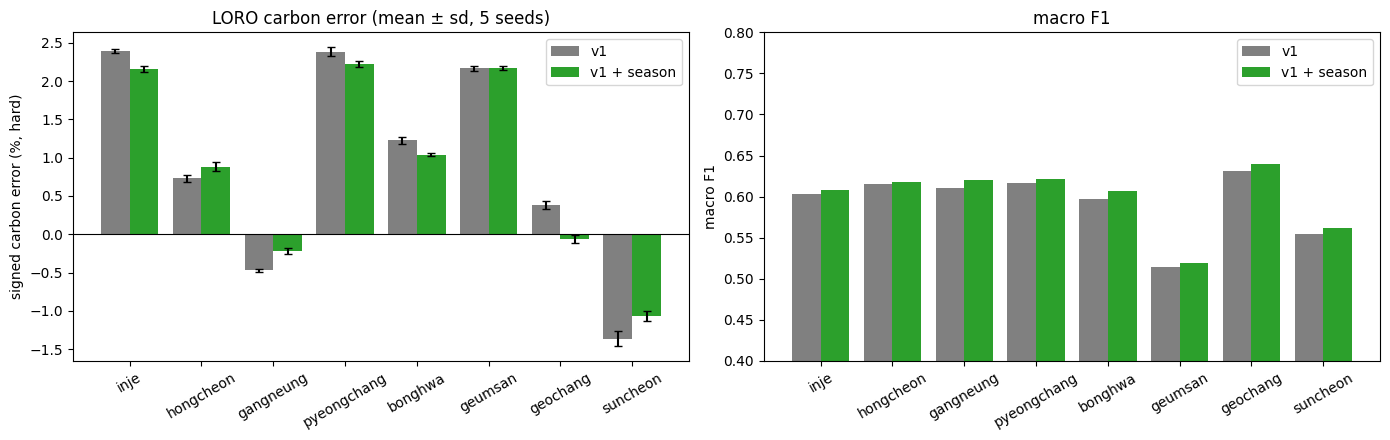

→ [8]·[9]·[10] 출력을 채팅에 붙여넣기


In [12]:
# [11] 그림 → exp6a.png  (Colab 기본 폰트에 한글이 없어 영문 표기)
x = np.arange(nr)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for off, key, lab, col in ((-.2, 'v1_eh', 'v1', 'gray'), (.2, 'sea_eh', 'v1 + season', 'tab:green')):
    ax[0].bar(x + off, R[key].mean(0), width=.4, yerr=R[key].std(0, ddof=1), capsize=3, color=col, label=lab)
ax[0].axhline(0, c='k', lw=.8)
ax[0].set_xticks(x); ax[0].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[0].set_ylabel('signed carbon error (%, hard)'); ax[0].set_title('LORO carbon error (mean ± sd, 5 seeds)'); ax[0].legend()
for off, key, lab, col in ((-.2, 'v1_f1', 'v1', 'gray'), (.2, 'sea_f1', 'v1 + season', 'tab:green')):
    ax[1].bar(x + off, R[key].mean(0), width=.4, color=col, label=lab)
ax[1].set_ylim(0.4, 0.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(TRAIN_REGIONS, rotation=30)
ax[1].set_ylabel('macro F1'); ax[1].set_title('macro F1'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT}/exp6a.png', dpi=150); plt.show()
print('→ [8]·[9]·[10] 출력을 채팅에 붙여넣기')